# Is This Game Fun? Personalized Game Recommendation on Steam

**CSE 158/258, Assignment 2 (Fall 2026)**

**Team:** TODO (names, or leave blank to blind the submission)

---

> **Before exporting:** peer graders will **not** run this notebook. Run every cell top to bottom
> (*Kernel -> Restart & Run All*), check that every output and plot is visible, save, and only then
> export to HTML (see the last section). A cell without an output looks unfinished to graders.

## Overview

"Fun" is not a column in any dataset, so we have to define it before we can predict it. We study
personalized game recommendation on the Steam "Australian users" dataset and compare two proxies for
whether a user finds a game fun: an **implicit** signal (how much the user played the game,
relative to how much that user plays games in general) and an **explicit** signal (whether the
user's review recommends the game). We compare popularity and random baselines with Bayesian
Personalized Ranking (BPR) trained on ownership, a **Fun-BPR** variant trained only to separate
heavily played owned games from barely played ones, and a latent factor model of log playtime. Then we
check whether the games our models consider "fun" agree with what users explicitly recommend.

TODO: replace this paragraph with a 3-4 sentence summary of the actual findings once results are in.

## Table of contents

0. Title & Overview (this section)
1. [Predictive Task](#1.-Predictive-Task)
2. [Exploratory Analysis & Preprocessing](#2.-Exploratory-Analysis-&-Preprocessing)
3. [Modeling](#3.-Modeling)
4. [Evaluation](#4.-Evaluation)
5. [Related Work](#5.-Related-Work)
6. [Conclusion](#6.-Conclusion)
7. [Export to HTML](#7.-Export-to-HTML)

Sections 1-5 map one-to-one onto the five graded rubric sections (5 marks each). Section 6 summarizes
and Section 7 is the submission checklist.

## Team conventions (delete before submitting)

- Names follow the lecture code style: `camelCase` variables (`itemsPerUser`, `usersPerItem`),
  `defaultdict` for lookups, TensorFlow `tf.keras.Model` subclasses for latent factor models.
- Every function has a docstring with `Parameters` / `Returns`.
- Do not hard-code numbers into markdown. Print them from code so the text cannot drift from the results.
- Data files live in `data/` (not committed). Paths are relative to this notebook.

In [1]:
import ast
import gzip
import os
import random
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 158
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = 'data'
FILES = {
    'reviews': 'australian_user_reviews.json',
    'items': 'australian_users_items.json',
    'games': 'steam_games.json',
    'bundles': 'bundle_data.json',  # optional, not used yet
}

# Plot styling: one hue for single-series charts; a validated blue/orange pair when two series
# appear together. Grid and axes are kept recessive so the data carries the ink.
COLOR_PRIMARY = '#2a78d6'
COLOR_SECONDARY = '#eb6834'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#0b0b0b',
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.6,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'legend.frameon': False,
})
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# 1. Predictive Task

**What this section is for.** Defining exactly what we predict, how we measure success, what we
compare against, and how we will know whether the predictions mean anything. Graders read this
first, so every later section should trace back to a sentence here.

**Rubric: 4 vs. 5.**
- *4:* The task is precise (inputs, outputs, label definition), the metrics and baselines are named
  and justified, and the validity check is stated.
- *5:* The definition of "fun" is motivated by evidence (link forward to the EDA in Section 2), the
  hypotheses are explicit and falsifiable, and we explain why the task is non-trivial (e.g. why
  popularity alone does well on ownership but should fail on "fun").

**TODO checklist**
- [ ] Finalize the definition of "played a lot" (median vs. another quantile; include or exclude zero-playtime games)
- [ ] State our hypotheses explicitly (H1, H2, ... below)
- [ ] Confirm the hold-out sizes for the split (Section 3.1)
- [ ] Keep this section in sync with Sections 3 and 4

## 1.1 Task definition

Let $U$ be the set of users, $I$ the set of games, $I_u \subseteq I$ the games user $u$ owns, and
$t_{u,i}$ the total playtime (minutes) of user $u$ on game $i$.

We study three related tasks:

| | Task | Input | Output | Main metric |
|---|---|---|---|---|
| **A** | Ownership ranking | user $u$ | ranking of games $u$ does not yet own | AUC, Hit@10, NDCG@10 |
| **B** | "Fun" ranking | user $u$, set of games $u$ owns | ranking of owned games by how much $u$ will enjoy them | AUC, Hit@10, NDCG@10 |
| **C** | Playtime regression | pair $(u, i)$ with $i \in I_u$ | $\log(1 + t_{u,i})$ | MSE |
| (D) | Recommend classification *(optional)* | review text (+ features) | `recommend` $\in \{0, 1\}$ | AUC, balanced accuracy |

## 1.2 Operationalizing "fun"

**Implicit proxy: relative playtime.** Raw playtime is not comparable across users (some people
play hundreds of hours a week). So we label a game as *played a lot* relative to the user's own
habits:

$$
y^{\text{play}}_{u,i} = \mathbb{1}\left[\, t_{u,i} > \operatorname{median}_{j \in I_u} t_{u,j} \,\right], \qquad i \in I_u .
$$

**Explicit proxy: recommendation.** For the subset of (user, game) pairs with a review,

$$
y^{\text{rec}}_{u,i} = \mathbb{1}\left[\, u \text{ recommends } i \,\right].
$$

The two proxies can disagree. A "grindy" game can have huge playtime and still not be recommended,
and a short story game can be loved but barely played. Measuring that disagreement is part of the
validity check.

TODO: decide and justify whether zero-playtime games count towards the median (see the EDA in Section 2.4).

## 1.3 Hypotheses

- **H1:** Popularity is a strong baseline for Task A (ownership) but close to random for Task B, because
  in Task B both candidate games are already owned.
- **H2:** Fun-BPR beats standard BPR on Task B, while standard BPR wins on Task A.
- **H3:** Games ranked highly by Fun-BPR are recommended more often by users who reviewed them than
  games ranked low.
- TODO: add or remove hypotheses as results come in.

## 1.4 Evaluation plan, baselines, validity

- **Metrics:** AUC, Hit@10 and NDCG@10 for ranking; MSE on $\log(1+t)$ for regression; AUC and
  balanced accuracy for `recommend`. Section 4.1 justifies each choice.
- **Baselines:** random ranking; popularity (most owned, and most played).
- **Split:** per user, hold out a few positives for validation and a few for test. Never use a random
  row split, which can leave a user with nothing in training.
- **Validity:** (1) compare model rankings with explicit `recommend` labels on reviewed games;
  (2) inspect where playtime and `recommend` disagree; (3) check that improvements over the baselines are
  statistically significant: bootstrap confidence intervals over users, paired tests between models,
  and variance across random seeds (Section 4.4).

# 2. Exploratory Analysis & Preprocessing

**What this section is for.** Where the data comes from, what we did to it, and what it looks
like. Every preprocessing decision and every modeling choice later on should be justified by
something shown here.

**Rubric: 4 vs. 5.**
- *4:* Clear provenance (source, collection method, intended use), every processing step reported,
  and statistics, tables and plots that support the discussion.
- *5:* The EDA directly drives decisions, e.g. showing why playtime must be log-transformed and
  normalized per user, or quantifying how often playtime and `recommend` disagree. Data-quality issues
  (duplicates, missing years, reviews of unowned games) are found and handled deliberately.

**TODO checklist**
- [ ] Verify the provenance paragraph against the dataset page and the papers in Section 5
- [ ] Decide what to do with reviews of games that are not in the reviewer's library
- [ ] Add a genre/tag plot from `steam_games.json` if it supports the story
- [ ] Write 1-2 sentences of interpretation under every plot

## 2.1 Data context

The data comes from Julian McAuley's recommender systems dataset collection
(<https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data>). It was scraped from public
Steam community profiles (the "Australian users" subset) and the Steam store, and is cited
there by Kang & McAuley (ICDM 2018), Wan & McAuley (RecSys 2018) and Pathak et al. (SIGIR 2017).
TODO: verify these details on the dataset page and describe the collection period and method.

| File | One record is... | Used for |
|---|---|---|
| `australian_users_items.json` | a user and their full library (`items`, each with `playtime_forever`, `playtime_2weeks`) | implicit feedback, Tasks A-C |
| `australian_user_reviews.json` | a user and their reviews (`reviews`, each with `item_id`, `recommend`, `review`, `posted`, ...) | explicit feedback, validity check, Task D |
| `steam_games.json` | one game's store metadata (`genres`, `tags`, `price`, `developer`, ...) | names and genres for interpretation |
| `bundle_data.json` *(optional)* | a store bundle and its games | not used yet |

All files are "loose JSON": every line is a **Python dict literal** (single quotes, `True`/`False`,
`u'...'` strings), so we parse each line with `ast.literal_eval` rather than `json.loads`.
Playtimes are in **minutes**, which is the Steam API convention.

## 2.2 Loading

In [2]:
def resolvePath(fileName, dataDir=DATA_DIR):
    """Find a data file, accepting either the plain or the gzipped version.

    Parameters
    ----------
    fileName : str
        File name without the `.gz` suffix, e.g. 'steam_games.json'.
    dataDir : str
        Directory containing the data files.

    Returns
    -------
    str
        Path to the existing file (plain preferred, otherwise `.gz`).
    """
    for candidate in (fileName, fileName + '.gz'):
        path = os.path.join(dataDir, candidate)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f'{fileName}(.gz) not found in {dataDir}/')


def readLooseJson(path):
    """Yield one record per line from a "loose JSON" (Python dict literal) file.

    Parameters
    ----------
    path : str
        Path to a `.json` or `.json.gz` file with one Python dict literal per line.

    Returns
    -------
    generator of dict
        Parsed records, in file order.
    """
    opener = gzip.open if path.endswith('.gz') else open
    with opener(path, 'rt', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                yield ast.literal_eval(line)


print(f'{"file":35s} {"size (MB)":>10s}')
for name in sorted(os.listdir(DATA_DIR)):
    print(f'{name:35s} {os.path.getsize(os.path.join(DATA_DIR, name)) / 1e6:10.1f}')

file                                 size (MB)
australian_user_reviews.json              26.3
australian_users_items.json              553.1
bundle_data.json                           0.8
steam_games.json                          21.2


In [3]:
def loadUserItems(path):
    """Flatten user libraries into one row per (user, game) pair.

    Duplicate user records are kept here (tagged by `line`) and removed in Section 2.3, so the
    cleaning step is visible.

    Parameters
    ----------
    path : str
        Path to `australian_users_items.json(.gz)`.

    Returns
    -------
    interactions : pd.DataFrame
        Columns: line, user_id, item_id, playtime_forever, playtime_2weeks.
    userLines : pd.DataFrame
        One row per line in the file. Columns: line, user_id, items_count, n_items.
    itemNames : dict
        item_id -> item_name as it appears in user libraries.
    """
    cols = defaultdict(list)
    userRows = []
    itemNames = {}
    for line, d in enumerate(readLooseJson(path)):
        userRows.append((line, d['user_id'], d['items_count'], len(d['items'])))
        for it in d['items']:
            cols['line'].append(line)
            cols['user_id'].append(d['user_id'])
            cols['item_id'].append(it['item_id'])
            cols['playtime_forever'].append(it['playtime_forever'])
            cols['playtime_2weeks'].append(it['playtime_2weeks'])
            itemNames[it['item_id']] = it['item_name']
    interactions = pd.DataFrame(cols)
    userLines = pd.DataFrame(userRows, columns=['line', 'user_id', 'items_count', 'n_items'])
    return interactions, userLines, itemNames


def loadReviews(path):
    """Flatten user review records into one row per review.

    Parameters
    ----------
    path : str
        Path to `australian_user_reviews.json(.gz)`.

    Returns
    -------
    pd.DataFrame
        Columns: line, user_id, item_id, recommend, review, posted, last_edited, funny, helpful.
    """
    rows = []
    for line, d in enumerate(readLooseJson(path)):
        for r in d['reviews']:
            rows.append({'line': line, 'user_id': d['user_id'], **r})
    return pd.DataFrame(rows)


def loadGames(path):
    """Load game metadata into a DataFrame (one row per record; fields can be missing).

    Parameters
    ----------
    path : str
        Path to `steam_games.json(.gz)`.

    Returns
    -------
    pd.DataFrame
        One row per game record. Missing fields are NaN.
    """
    return pd.DataFrame(list(readLooseJson(path)))

In [4]:
# The items file is ~550 MB; parsing it with ast.literal_eval takes a minute or two.
interactionsRaw, userLines, itemNames = loadUserItems(resolvePath(FILES['items']))
reviewsRaw = loadReviews(resolvePath(FILES['reviews']))
games = loadGames(resolvePath(FILES['games']))

print('items file   :', f'{len(userLines):,} user lines, {len(interactionsRaw):,} (user, game) rows')
print('reviews file :', f'{reviewsRaw["line"].nunique():,} user lines with >= 1 review, {len(reviewsRaw):,} reviews')
print('games file   :', f'{len(games):,} records')
print()
print('review fields:', list(reviewsRaw.columns))
print('game fields  :', list(games.columns))

items file   : 88,310 user lines, 5,153,209 (user, game) rows
reviews file : 25,771 user lines with >= 1 review, 59,305 reviews
games file   : 32,135 records

review fields: ['line', 'user_id', 'funny', 'posted', 'last_edited', 'item_id', 'helpful', 'recommend', 'review']
game fields  : ['publisher', 'genres', 'app_name', 'title', 'url', 'release_date', 'tags', 'discount_price', 'reviews_url', 'specs', 'price', 'early_access', 'id', 'developer', 'sentiment', 'metascore']


In [5]:
# Field coverage in the game metadata: many fields are missing for a large share of games.
games.notna().mean().sort_values(ascending=False).rename('share non-missing').to_frame()

,share non-missing
url,1.0000
early_access,1.0000
reviews_url,0.9999
app_name,0.9999
id,0.9999
tags,0.9949
specs,0.9792
price,0.9571
title,0.9362
release_date,0.9357


## 2.3 Cleaning

Steps, each one checked in the code below:

1. **Duplicate users.** Some `user_id`s appear on more than one line of a file. We keep the first occurrence.
2. **Empty libraries.** Users who own nothing (or have a private library) carry no signal for
   Tasks A-C. We drop them from the interaction table.
3. **Duplicate reviews.** We keep one review per (user, game).
4. **Review dates.** `posted` looks like `"Posted November 5, 2011."`. Reviews from the current
   year omit the year, so we parse what we can and flag the rest.
5. **Reviews of unowned games.** Some reviewed games are not in the reviewer's scraped library
   (e.g. refunded, gifted away, or the two crawls happened at different times). We keep them for the text task
   but exclude them from any analysis that needs playtime.
6. **Game metadata.** We drop records without an `id` and deduplicate on `id`.

In [6]:
# 1-2. Deduplicate users in the items file (keep first line) and drop empty libraries.
firstLine = userLines.groupby('user_id')['line'].min()
dupUserLines = len(userLines) - len(firstLine)
interactions = interactionsRaw[interactionsRaw['line'].isin(firstLine.values)].drop(columns='line').reset_index(drop=True)
del interactionsRaw  # free ~5M rows of memory

usersDedup = userLines[userLines['line'].isin(firstLine.values)]
nEmpty = int((usersDedup['n_items'] == 0).sum())
assert (usersDedup['items_count'] == usersDedup['n_items']).all(), 'items_count disagrees with the items list'
assert not interactions.duplicated(['user_id', 'item_id']).any(), 'duplicate (user, game) pairs remain'

print(f'duplicate user lines removed (items) : {dupUserLines:,}')
print(f'users with an empty library          : {nEmpty:,} of {len(usersDedup):,}')

duplicate user lines removed (items) : 684
users with an empty library          : 16,714 of 87,626


In [7]:
# 3-5. Deduplicate reviews, parse dates, flag reviews of games not in the reviewer's library.
MONTHS = {m: i for i, m in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                      'August', 'September', 'October', 'November', 'December'], 1)}


def parsePostedDate(posted):
    """Parse a Steam review date string.

    Parameters
    ----------
    posted : str
        e.g. 'Posted November 5, 2011.' or 'Posted July 15.' (year omitted for the current year).

    Returns
    -------
    tuple (pd.Timestamp or pd.NaT, bool)
        The parsed date (NaT if the year is missing or the string is unparseable), and whether a
        year was present.
    """
    m = re.match(r'Posted (\w+) (\d{1,2})(?:, (\d{4}))?\.', posted or '')
    if not m or m.group(1) not in MONTHS:
        return pd.NaT, False
    if m.group(3) is None:
        return pd.NaT, False
    return pd.Timestamp(int(m.group(3)), MONTHS[m.group(1)], int(m.group(2))), True


reviews = reviewsRaw.drop_duplicates(['user_id', 'item_id'], keep='first').drop(columns='line').reset_index(drop=True)
parsed = reviews['posted'].map(parsePostedDate)
reviews['date'] = parsed.map(lambda x: x[0])
reviews['has_year'] = parsed.map(lambda x: x[1])

ownedPairs = pd.MultiIndex.from_frame(interactions[['user_id', 'item_id']])
reviews['in_library'] = pd.MultiIndex.from_frame(reviews[['user_id', 'item_id']]).isin(ownedPairs)

print(f'duplicate (user, game) reviews removed : {len(reviewsRaw) - len(reviews):,}')
print(f'reviews without a parseable year       : {(~reviews["has_year"]).mean():.2%}')
print(f'reviews of games in reviewer library   : {reviews["in_library"].mean():.2%}')
if reviews['has_year'].any():
    print(f'review date range (with year)          : {reviews["date"].min().date()} to {reviews["date"].max().date()}')

duplicate (user, game) reviews removed : 874
reviews without a parseable year       : 17.00%
reviews of games in reviewer library   : 75.62%
review date range (with year)          : 2010-10-16 to 2015-12-31


In [8]:
# 6. Game metadata: drop records without an id, deduplicate on id.
gamesClean = games.dropna(subset=['id']).drop_duplicates('id').set_index('id')
ownedGames = set(interactions['item_id'])
print(f'game records with an id      : {len(gamesClean):,}')
print(f'owned games with metadata    : {len(ownedGames & set(gamesClean.index)):,} of {len(ownedGames):,}')

game records with an id      : 32,132
owned games with metadata    : 9,192 of 10,978


### Summary statistics

All numbers below are computed from the cleaned tables.

In [9]:
nonEmptyUsers = interactions['user_id'].nunique()
summary = pd.Series({
    'users (unique, items file)': usersDedup['user_id'].nunique(),
    'users with a non-empty library': nonEmptyUsers,
    'games owned by >= 1 user': interactions['item_id'].nunique(),
    'games in metadata': len(gamesClean),
    'user-game pairs (ownership)': len(interactions),
    'reviews (deduplicated)': len(reviews),
    'users with >= 1 review': reviews['user_id'].nunique(),
    'games with >= 1 review': reviews['item_id'].nunique(),
    'share of reviews with recommend = True': reviews['recommend'].mean(),
    'share of owned games with playtime 0': (interactions['playtime_forever'] == 0).mean(),
    'share of owned games played in last 2 weeks': (interactions['playtime_2weeks'] > 0).mean(),
    'density of user x game matrix': len(interactions) / (nonEmptyUsers * interactions['item_id'].nunique()),
}, name='value')
summary.to_frame().style.format(lambda v: f'{v:.4f}' if v < 1 else f'{v:,.0f}')

,value
"users (unique, items file)","87,626"
users with a non-empty library,"70,912"
games owned by >= 1 user,"10,978"
games in metadata,"32,132"
user-game pairs (ownership),"5,094,082"
reviews (deduplicated),"58,431"
users with >= 1 review,"25,458"
games with >= 1 review,"3,682"
share of reviews with recommend = True,0.8847
share of owned games with playtime 0,0.3627


## 2.4 Exploratory analysis

### Playtime is extremely skewed, so we model $\log(1 + t)$

TODO: interpret. Note the spike at zero, the long tail, and why a squared error on raw minutes would be dominated by a handful of users.

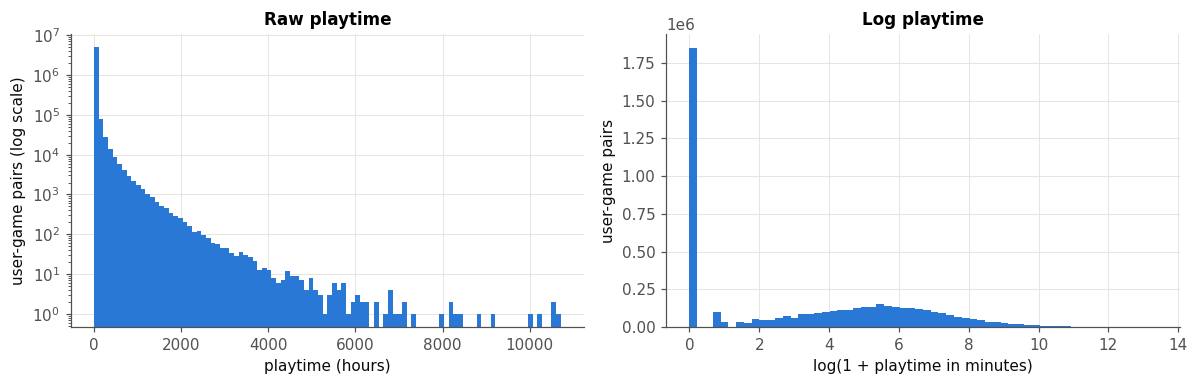

playtime = 0 for 36.27% of owned games
quantiles of playtime (minutes):
0.2500        0.0000
0.5000       34.0000
0.7500      355.0000
0.9000    1,575.0000
0.9900   17,935.0000


In [10]:
pt = interactions['playtime_forever'].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(pt / 60, bins=100, color=COLOR_PRIMARY)
axes[0].set_yscale('log')
axes[0].set_xlabel('playtime (hours)')
axes[0].set_ylabel('user-game pairs (log scale)')
axes[0].set_title('Raw playtime')

axes[1].hist(np.log1p(pt), bins=60, color=COLOR_PRIMARY)
axes[1].set_xlabel('log(1 + playtime in minutes)')
axes[1].set_ylabel('user-game pairs')
axes[1].set_title('Log playtime')
plt.tight_layout()
plt.show()

print(f'playtime = 0 for {np.mean(pt == 0):.2%} of owned games')
print('quantiles of playtime (minutes):')
print(pd.Series(pt).quantile([0.25, 0.5, 0.75, 0.9, 0.99]).to_string())

### Library sizes and game popularity are long-tailed

TODO: interpret. Long tails on both sides: the popularity baseline will be strong for ownership, and many games have too few owners to learn good embeddings.

TODO: some library entries are beta/test companions of a game (e.g. a "Beta" item with exactly the same owner count as the base game). Decide whether to merge or drop them; they inflate easy positives.

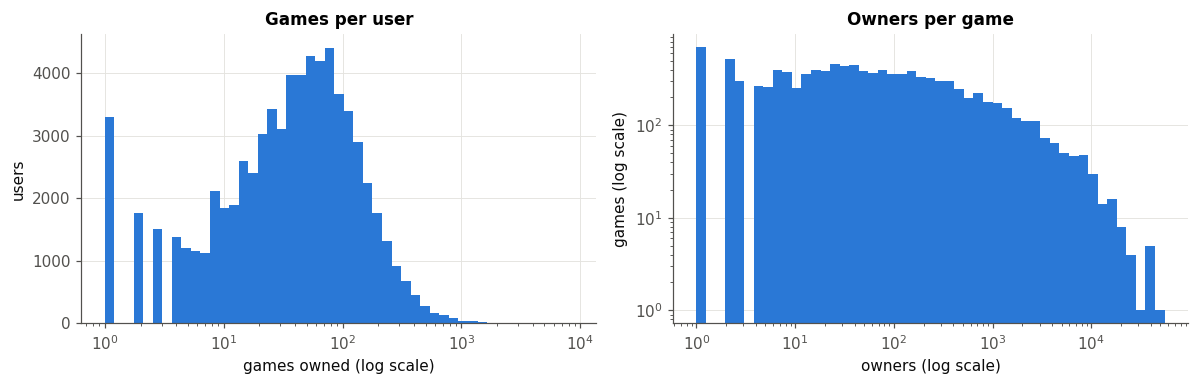

games per user : {'mean': 71.8, '50%': 40.0, 'max': 7762.0}
owners per game: {'mean': 464.0, '50%': 43.0, 'max': 49136.0}


,item_id,game,owners
0,205790,Dota 2 Test,49136
1,730,Counter-Strike: Global Offensive,43331
2,4000,Garry's Mod,42849
3,304930,Unturned,38278
4,550,Left 4 Dead 2,36661
5,223530,Left 4 Dead 2 Beta,36661
6,105600,Terraria,28934
7,230410,Warframe,25516
8,620,Portal 2,24206
9,240,Counter-Strike: Source,23952


In [11]:
gamesPerUser = interactions.groupby('user_id').size()
ownersPerGame = interactions.groupby('item_id').size()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(0, np.log10(gamesPerUser.max()) + 0.05, 50)
axes[0].hist(gamesPerUser, bins=bins, color=COLOR_PRIMARY)
axes[0].set_xscale('log')
axes[0].set_xlabel('games owned (log scale)')
axes[0].set_ylabel('users')
axes[0].set_title('Games per user')

bins = np.logspace(0, np.log10(ownersPerGame.max()) + 0.05, 50)
axes[1].hist(ownersPerGame, bins=bins, color=COLOR_PRIMARY)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('owners (log scale)')
axes[1].set_ylabel('games (log scale)')
axes[1].set_title('Owners per game')
plt.tight_layout()
plt.show()

print('games per user :', gamesPerUser.describe()[['mean', '50%', 'max']].round(1).to_dict())
print('owners per game:', ownersPerGame.describe()[['mean', '50%', 'max']].round(1).to_dict())
top = ownersPerGame.sort_values(ascending=False).head(10)
storeNames = gamesClean['app_name'].dropna().to_dict()
pd.DataFrame({'item_id': top.index,
              'game': [storeNames.get(i, itemNames.get(i, i)) for i in top.index],
              'owners': top.values})

### `recommend` is heavily imbalanced

TODO: interpret. The majority class already gives high accuracy, so plain accuracy is not a useful metric for Task D (see Section 4.1).

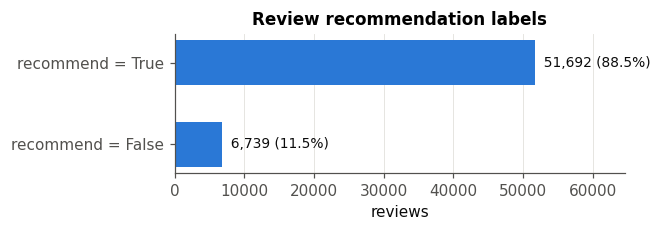

share of reviewing users who recommend every game they review: 80.29%


In [12]:
recCounts = reviews['recommend'].value_counts().reindex([True, False])

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(['recommend = True', 'recommend = False'], recCounts.values, color=COLOR_PRIMARY, height=0.55)
for y, v in enumerate(recCounts.values):
    ax.text(v, y, f'  {v:,} ({v / recCounts.sum():.1%})', va='center', color='#0b0b0b', fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('reviews')
ax.set_title('Review recommendation labels')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, recCounts.max() * 1.25)
plt.tight_layout()
plt.show()

perUserRate = reviews.groupby('user_id')['recommend'].mean()
print(f'share of reviewing users who recommend every game they review: {(perUserRate == 1).mean():.2%}')

### Do playtime and `recommend` agree?

We join reviews with the reviewer's library (only reviews of owned games, see Section 2.3) and compare the
explicit label with the implicit "played a lot" label from Section 1.2.

TODO: interpret. Where is the recommend rate lowest? Are disagreements concentrated in particular games or genres?

In [13]:
def addRelativePlaytimeLabel(df, includeZeros=True):
    """Label each owned game as 'played a lot' relative to its owner's median playtime.

    Parameters
    ----------
    df : pd.DataFrame
        Interaction table with columns user_id, playtime_forever.
    includeZeros : bool
        If True, the per-user median is taken over all owned games (including never-played ones);
        if False, only over games with playtime > 0.

    Returns
    -------
    pd.DataFrame
        Copy of `df` with added columns `user_median` and `played_a_lot` (bool).
    """
    out = df.copy()
    base = out['playtime_forever'] if includeZeros else out['playtime_forever'].where(out['playtime_forever'] > 0)
    out['user_median'] = base.groupby(out['user_id']).transform('median')
    out['played_a_lot'] = out['playtime_forever'] > out['user_median']
    return out


interactions = addRelativePlaytimeLabel(interactions, includeZeros=True)
print(f'share of owned games labeled played_a_lot: {interactions["played_a_lot"].mean():.2%}')
print(f'users whose median playtime is 0         : {(interactions.groupby("user_id")["user_median"].first() == 0).mean():.2%}')

joined = reviews[reviews['in_library']].merge(
    interactions[['user_id', 'item_id', 'playtime_forever', 'user_median', 'played_a_lot']],
    on=['user_id', 'item_id'], how='inner')
print(f'reviewed and owned (user, game) pairs     : {len(joined):,}')
print(f'agreement (played_a_lot == recommend)    : {(joined["played_a_lot"] == joined["recommend"]).mean():.2%}')
pd.crosstab(joined['played_a_lot'], joined['recommend'], normalize='index', margins=False).rename_axis(
    index='played_a_lot', columns='recommend')

share of owned games labeled played_a_lot: 46.39%
users whose median playtime is 0         : 15.71%


reviewed and owned (user, game) pairs     : 44,186
agreement (played_a_lot == recommend)    : 86.02%


recommend,False,True
played_a_lot,,
False,0.3124,0.6876
True,0.0947,0.9053


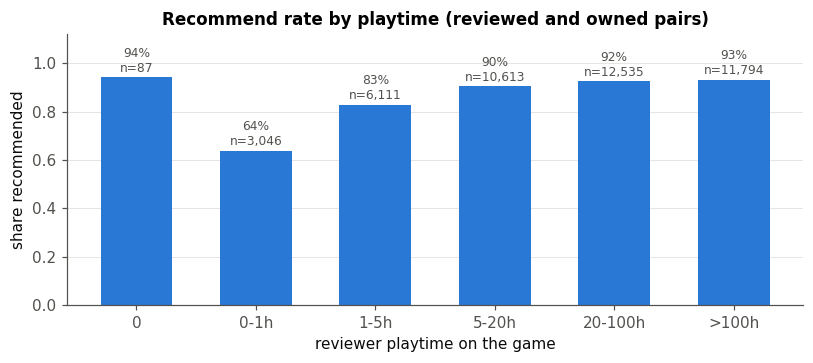

,mean,size
playtime_bin,,
0,0.9425,87
0-1h,0.6389,3046
1-5h,0.8287,6111
5-20h,0.9038,10613
20-100h,0.9249,12535
>100h,0.9320,11794


In [14]:
edges = [-1, 0, 60, 5 * 60, 20 * 60, 100 * 60, np.inf]
labels = ['0', '0-1h', '1-5h', '5-20h', '20-100h', '>100h']
joined['playtime_bin'] = pd.cut(joined['playtime_forever'], bins=edges, labels=labels)
byBin = joined.groupby('playtime_bin', observed=False)['recommend'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(byBin.index.astype(str), byBin['mean'], color=COLOR_PRIMARY, width=0.6)
for x, (rate, n) in enumerate(zip(byBin['mean'], byBin['size'])):
    ax.text(x, rate + 0.01, f'{rate:.0%}\nn={n:,}', ha='center', va='bottom', fontsize=8, color='#52514e')
ax.set_ylim(0, 1.12)
ax.set_xlabel('reviewer playtime on the game')
ax.set_ylabel('share recommended')
ax.set_title('Recommend rate by playtime (reviewed and owned pairs)')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()
byBin

# 3. Modeling

**What this section is for.** Formulating the tasks as ML problems, presenting each model, and
explaining the design choices and trade-offs. Graders follow this code during the video
walkthrough, so keep each model in its own subsection.

**Rubric: 4 vs. 5.**
- *4:* Inputs, outputs and objective are clear for every model; the advantages and disadvantages
  (complexity, efficiency, implementation challenges) are discussed; the code is walked through.
- *5:* Fun-BPR is well motivated and analyzed (ablations: threshold choice, negative sampling),
  hyperparameters are tuned on validation data with the tuning shown, and scalability is
  discussed with actual timings.

**TODO checklist**
- [ ] Implement `buildIndex`, `splitPerUser` (3.1)
- [ ] Implement the baselines (3.2)
- [ ] Implement the BPR model, samplers and training loop (3.3, 3.4)
- [ ] Implement the latent factor model (3.5)
- [ ] (Optional) TF-IDF + logistic regression for `recommend` (3.6)
- [ ] Tune $K$ and $\lambda$ on the validation split; record the grid and the chosen values
- [ ] Fill in the trade-offs table (3.7) with measured training times

## 3.0 Formulation and course alignment

| Model | Input | Output | Objective | Course material |
|---|---|---|---|---|
| Random | $u$ | random scores | none | trivial baseline |
| Popularity | $u$ | $\#\text{owners}(i)$ or total playtime of $i$ | none | Recommendation lecture; Ethics lecture (`countsPerItem`) |
| BPR | $u$ | $x_{u,i}$ | pairwise log-likelihood, owned vs. unowned | Recommendation lecture ("BPR (implicit)", TensorFlow version from PML ch. 5) |
| **Fun-BPR** (ours) | $u$ | $x_{u,i}$ | pairwise log-likelihood, high-play vs. low-play *owned* | same model as BPR; only the sampling of $(i, j)$ changes |
| Latent factor model | $(u, i)$ | $\hat r_{u,i}$ | regularized MSE on $\log(1+t_{u,i})$ | Recommendation lecture (latent factor models with biases) |
| TF-IDF + logistic regression | review text | $P(\text{recommend})$ | regularized log-likelihood | Text Mining and Classification lectures |

**BPR** scores a (user, game) pair as

$$
x_{u,i} = \beta_i + \gamma_u \cdot \gamma_i ,
$$

and maximizes the probability that a positive game $i$ is ranked above a negative game $j$:

$$
\max_{\Theta} \sum_{(u,i,j) \in D} \ln \sigma\!\left(x_{u,i} - x_{u,j}\right) - \lambda \lVert \Theta \rVert_2^2 .
$$

Standard BPR and Fun-BPR differ only in how the triples $D$ are formed:

| | positive $i$ | negative $j$ |
|---|---|---|
| Standard BPR | $i \in I_u$ (owned) | $j \notin I_u$ (random unowned game) |
| Fun-BPR | $i \in I_u$ with $y^{\text{play}}_{u,i} = 1$ | $j \in I_u$ with $y^{\text{play}}_{u,j} = 0$ |

Because both games in a Fun-BPR triple are owned, popularity (owning) cannot explain the
difference, and the model has to learn which owned games get played.

**Latent factor model** (pointwise regression on log playtime):

$$
\hat r_{u,i} = \alpha + \beta_u + \beta_i + \gamma_u \cdot \gamma_i, \qquad
r_{u,i} = \log(1 + t_{u,i}),
$$

$$
\min_{\alpha, \beta, \gamma} \sum_{(u,i) \in \text{train}} \left(\hat r_{u,i} - r_{u,i}\right)^2
+ \lambda \left( \sum_u \beta_u^2 + \sum_i \beta_i^2 + \sum_u \lVert\gamma_u\rVert_2^2 + \sum_i \lVert\gamma_i\rVert_2^2 \right).
$$

The models follow the lecture code (PML ch. 5): `tf.keras.Model` subclasses with `tf.Variable`
parameters initialized from $\mathcal{N}(0, 0.001^2)$, a `tf.GradientTape` training step and the Adam optimizer.

In [15]:
import tensorflow as tf

tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 3.1 Indexing and train / validation / test split

We split **per user**: for each user with enough games, hold out `nHoldout` positives for
validation and `nHoldout` for test, and keep the rest for training. A random row split could
put all of a user's games in the test set, leaving no training signal for that user.

For Fun-BPR the held-out pairs must contain both a high-play and a low-play owned game, so that
Task B can be evaluated on the same users.

TODO: decide `nHoldout` and the minimum library size, and report how many users are kept.

In [16]:
def buildIndex(interactions):
    """Map raw user and item ids to contiguous integer indices (needed for embedding tables).

    Parameters
    ----------
    interactions : pd.DataFrame
        Interaction table with columns user_id, item_id.

    Returns
    -------
    userIDs : dict
        user_id -> int index in [0, nUsers).
    itemIDs : dict
        item_id -> int index in [0, nItems).
    """
    # TODO: assign indices in order of first appearance (or sorted) for users and items.
    raise NotImplementedError


def splitPerUser(interactions, nHoldout=1, minItems=5, seed=SEED):
    """Leave-n-out split per user, stratified on the played_a_lot label.

    Parameters
    ----------
    interactions : pd.DataFrame
        Interaction table with columns user_id, item_id, playtime_forever, played_a_lot.
    nHoldout : int
        Number of high-play and number of low-play owned games held out per user, for each of
        validation and test.
    minItems : int
        Users with fewer owned games than this stay entirely in training.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    train, valid, test : pd.DataFrame
        Disjoint subsets of `interactions`. Every user in valid/test also appears in train.
    """
    # TODO:
    #   1. group by user; skip users with < minItems games (all their rows go to train)
    #   2. sample nHoldout played_a_lot == True rows and nHoldout == False rows for test,
    #      then the same again (from the remainder) for valid
    #   3. assert every valid/test user still has >= 1 high-play and >= 1 low-play game in train
    raise NotImplementedError


# TODO: uncomment once implemented
# userIDs, itemIDs = buildIndex(interactions)
# train, valid, test = splitPerUser(interactions, nHoldout=1, minItems=5)
# print(len(train), len(valid), len(test))

## 3.2 Baselines: random and popularity

- **Random:** score every game uniformly at random. Gives the chance level for every metric (AUC $\approx 0.5$).
- **Popularity (owned):** $s_{u,i} = |\{v : i \in I_v\}|$, the number of training users owning $i$.
- **Popularity (played):** $s_{u,i} = \sum_v t_{v,i}$ or the share of owners who played $i$ a lot.
  This version is the stronger baseline for Task B.

Neither baseline is personalized. Every user gets the same ranking.

In [17]:
def randomScores(nItems, seed=SEED):
    """Random baseline: one uniform score per item.

    Parameters
    ----------
    nItems : int
        Number of items.
    seed : int
        Random seed.

    Returns
    -------
    np.ndarray of shape (nItems,)
        Scores in [0, 1).
    """
    # TODO
    raise NotImplementedError


def popularityScores(train, itemIDs, mode='owned'):
    """Non-personalized popularity baseline.

    Parameters
    ----------
    train : pd.DataFrame
        Training interactions with columns item_id, playtime_forever, played_a_lot.
    itemIDs : dict
        item_id -> int index.
    mode : {'owned', 'playtime', 'played_a_lot'}
        'owned' counts owners; 'playtime' sums log(1 + playtime) over owners; 'played_a_lot'
        is the share of owners whose played_a_lot label is True.

    Returns
    -------
    np.ndarray of shape (len(itemIDs),)
        Popularity score per item index (0 for items never seen in train).
    """
    # TODO
    raise NotImplementedError

## 3.3 Standard BPR (owned vs. unowned)

In [18]:
class BPRbatch(tf.keras.Model):
    """Bayesian Personalized Ranking with x_ui = beta_i + gamma_u . gamma_i (lecture / PML ch. 5 style).

    Used both for standard BPR and Fun-BPR; only the triples fed to `call` differ.
    """

    def __init__(self, K, lamb, nUsers, nItems):
        """Create the parameters.

        Parameters
        ----------
        K : int
            Latent dimensionality.
        lamb : float
            L2 regularization strength.
        nUsers, nItems : int
            Sizes of the embedding tables.
        """
        super().__init__()
        # TODO: self.betaI  = tf.Variable(tf.random.normal([nItems], stddev=0.001))
        # TODO: self.gammaU = tf.Variable(tf.random.normal([nUsers, K], stddev=0.001))
        # TODO: self.gammaI = tf.Variable(tf.random.normal([nItems, K], stddev=0.001))
        self.lamb = lamb

    def score(self, sampleU, sampleI):
        """Compute x_ui for a batch of (user, item) index pairs.

        Parameters
        ----------
        sampleU, sampleI : tf.Tensor of int32, shape (B,)
            User and item indices.

        Returns
        -------
        tf.Tensor of float32, shape (B,)
            Scores x_ui.
        """
        # TODO: tf.nn.embedding_lookup for betaI, gammaU, gammaI; return beta_i + sum(gamma_u * gamma_i, axis=1)
        raise NotImplementedError

    def reg(self):
        """L2 penalty on all parameters.

        Returns
        -------
        tf.Tensor (scalar)
            lamb * (||betaI||^2 + ||gammaU||^2 + ||gammaI||^2).
        """
        # TODO
        raise NotImplementedError

    def call(self, sampleU, sampleI, sampleJ):
        """Negative mean BPR log-likelihood for a batch of triples.

        Parameters
        ----------
        sampleU, sampleI, sampleJ : tf.Tensor of int32, shape (B,)
            Users, positive items, negative items.

        Returns
        -------
        tf.Tensor (scalar)
            -mean(log sigmoid(x_ui - x_uj)).
        """
        # TODO
        raise NotImplementedError


def sampleStandardTriples(itemsPerUser, nItems, nSamples, rng):
    """Sample (u, i, j) with i owned by u and j a uniformly random game u does NOT own.

    Parameters
    ----------
    itemsPerUser : dict
        user index -> set of owned item indices (training data only).
    nItems : int
        Number of items to sample negatives from.
    nSamples : int
        Batch size.
    rng : random.Random
        Seeded random generator.

    Returns
    -------
    tuple of three lists of int
        sampleU, sampleI, sampleJ.
    """
    # TODO: rejection-sample j until j not in itemsPerUser[u]
    raise NotImplementedError


def trainingStep(model, optimizer, sampleU, sampleI, sampleJ):
    """One gradient step on a batch of BPR triples.

    Parameters
    ----------
    model : BPRbatch
        The model to update.
    optimizer : tf.keras.optimizers.Optimizer
        e.g. tf.keras.optimizers.Adam(0.1).
    sampleU, sampleI, sampleJ : list of int
        Batch of triples.

    Returns
    -------
    float
        Loss value (including regularization) for this batch.
    """
    # TODO:
    # with tf.GradientTape() as tape:
    #     loss = model(tf.convert_to_tensor(sampleU), ...) + model.reg()
    # grads = tape.gradient(loss, model.trainable_variables)
    # optimizer.apply_gradients(zip(grads, model.trainable_variables))
    raise NotImplementedError


# TODO: training loop, e.g.
# modelBPR = BPRbatch(K=5, lamb=1e-5, nUsers=len(userIDs), nItems=len(itemIDs))
# optimizer = tf.keras.optimizers.Adam(0.1)
# for step in range(nSteps):
#     batch = sampleStandardTriples(itemsPerUser, len(itemIDs), 50000, rng)
#     loss = trainingStep(modelBPR, optimizer, *batch)

## 3.4 Fun-BPR (high-play vs. low-play, both owned)

Same `BPRbatch` model, different triples. The item bias $\beta_i$ now learns "games that tend to
be played a lot by their owners" instead of "games that are owned a lot".

TODO: ablations. (a) median vs. top-quartile threshold; (b) including vs. excluding zero-playtime games
as negatives; (c) initializing from standard BPR then fine-tuning on fun triples.

In [19]:
def buildFunSets(train, userIDs, itemIDs):
    """Split each user's owned training games into high-play and low-play sets.

    Parameters
    ----------
    train : pd.DataFrame
        Training interactions with columns user_id, item_id, played_a_lot.
    userIDs, itemIDs : dict
        Raw id -> int index.

    Returns
    -------
    dict
        user index -> (list of high-play item indices, list of low-play item indices). Users
        missing either list are excluded, since they cannot form a triple.
    """
    # TODO
    raise NotImplementedError


def sampleFunTriples(funSets, nSamples, rng):
    """Sample (u, i, j) with i a high-play and j a low-play game, both owned by u.

    Parameters
    ----------
    funSets : dict
        Output of `buildFunSets`.
    nSamples : int
        Batch size.
    rng : random.Random
        Seeded random generator.

    Returns
    -------
    tuple of three lists of int
        sampleU, sampleI, sampleJ.
    """
    # TODO: sample u uniformly from funSets (or proportional to library size; discuss), then i, j
    raise NotImplementedError


# TODO: modelFun = BPRbatch(...); train with sampleFunTriples and the same trainingStep

## 3.5 Latent factor model on log playtime

In [20]:
class LatentFactorModel(tf.keras.Model):
    """r_hat(u, i) = alpha + beta_u + beta_i + gamma_u . gamma_i, fit to log(1 + playtime)."""

    def __init__(self, mu, K, lamb, nUsers, nItems):
        """Create the parameters.

        Parameters
        ----------
        mu : float
            Initial value of the global offset alpha (use the training mean of log(1 + t)).
        K : int
            Latent dimensionality.
        lamb : float
            L2 regularization strength.
        nUsers, nItems : int
            Sizes of the bias and embedding tables.
        """
        super().__init__()
        # TODO: self.alpha = tf.Variable(mu)
        # TODO: self.betaU, self.betaI, self.gammaU, self.gammaI (stddev=0.001)
        self.lamb = lamb

    def predict(self, u, i):
        """Predict log playtime for a single (user index, item index) pair.

        Parameters
        ----------
        u, i : int
            User and item indices.

        Returns
        -------
        float
            Predicted log(1 + playtime).
        """
        # TODO
        raise NotImplementedError

    def reg(self):
        """L2 penalty on biases and latent factors.

        Returns
        -------
        tf.Tensor (scalar)
        """
        # TODO
        raise NotImplementedError

    def call(self, sampleU, sampleI, sampleR):
        """Mean squared error on a batch.

        Parameters
        ----------
        sampleU, sampleI : tf.Tensor of int32, shape (B,)
            User and item indices.
        sampleR : tf.Tensor of float32, shape (B,)
            Targets log(1 + playtime).

        Returns
        -------
        tf.Tensor (scalar)
            Mean squared error.
        """
        # TODO
        raise NotImplementedError


# TODO: train with a GradientTape step analogous to `trainingStep`, early-stop on validation MSE.
# Note: this model can also rank games for Task B by its predicted playtime; evaluate it there too.

## 3.6 (Optional) TF-IDF + logistic regression on review text

Predict `recommend` from the review text. Labels are imbalanced, so use
`class_weight='balanced'` (the lecture's way of optimizing a balanced error measure) and evaluate
with AUC and balanced accuracy, not accuracy.

In [21]:
def trainRecommendClassifier(trainTexts, trainLabels, maxFeatures=5000, C=1.0):
    """Fit TF-IDF features + logistic regression to predict `recommend`.

    Parameters
    ----------
    trainTexts : list of str
        Review texts.
    trainLabels : list of bool
        `recommend` labels.
    maxFeatures : int
        Vocabulary size (most frequent terms).
    C : float
        Inverse regularization strength for LogisticRegression.

    Returns
    -------
    vectorizer : sklearn.feature_extraction.text.TfidfVectorizer
        Fitted vectorizer.
    clf : sklearn.linear_model.LogisticRegression
        Fitted classifier.
    """
    # TODO:
    # from sklearn.feature_extraction.text import TfidfVectorizer
    # from sklearn.linear_model import LogisticRegression
    # vectorizer = TfidfVectorizer(max_features=maxFeatures, lowercase=True)
    # clf = LogisticRegression(C=C, class_weight='balanced', max_iter=1000)
    raise NotImplementedError

## 3.7 Trade-offs

| | Random / Popularity | BPR / Fun-BPR (pairwise) | Latent factor model (pointwise) | TF-IDF + LR |
|---|---|---|---|---|
| Personalized | no | yes | yes | per review |
| Objective matches ranking metrics | n/a | yes (AUC is the pairwise objective) | no (MSE) | n/a |
| Uses playtime magnitude | optional | only through the label threshold | yes | no |
| Parameters | $O(\lvert I\rvert)$ | $O((\lvert U\rvert + \lvert I\rvert)K)$ | $O((\lvert U\rvert + \lvert I\rvert)(K+1))$ | $O(\text{vocabulary})$ |
| Cost per epoch | $O(\text{interactions})$ | $O(\text{samples} \cdot K)$ + negative sampling | $O(\text{interactions} \cdot K)$ | sparse matrix ops |
| Cold start | handles new users | fails for new users/games | fails for new users/games | needs text |
| Training time (measured) | TODO | TODO | TODO | TODO |

**Discussion points (TODO: write up):**
- *Pointwise vs. pairwise.* MSE treats every owned game as a regression target and is dominated by
  heavy players, while BPR only cares about order, which is what a recommender shows the user.
- *Implicit feedback.* Unowned does not mean disliked, so BPR's negatives are only "less preferred".
  Fun-BPR's negatives are informative because the user owns the game and chose not to play it.
- *Efficiency.* Negative sampling keeps BPR linear in the number of sampled triples instead of $\lvert U\rvert \cdot \lvert I\rvert$.

# 4. Evaluation

**What this section is for.** Justifying the metrics, implementing the evaluation protocol,
comparing every model with the baselines, and checking that the predictions are valid.

**Rubric: 4 vs. 5.**
- *4:* Metrics justified relative to the alternatives, baselines included, a results table and plots,
  and negative results explained.
- *5:* Both protocols (Task A and Task B) are reported for every model, with confidence intervals and
  paired significance tests against the baselines, a breakdown by user segment (e.g. small vs. large
  libraries), and a convincing validity check against explicit `recommend` labels.

**TODO checklist**
- [ ] Implement the metric functions (4.2) and test them on toy inputs with known answers
- [ ] Run all models on validation for tuning, then **once** on test
- [ ] Fill in the results table (4.3) from code, not by hand
- [ ] Significance (4.4): run both comparisons, Fun-BPR vs. BPR **and** Fun-BPR vs. Popularity (played), on Task B and Task A
- [ ] Plots (4.5): metric vs. $K$, metric by library size
- [ ] Validity check (4.6)

## 4.1 Metrics and why

**AUC** (covered in the Recommendation lecture). For user $u$ with held-out positives $P_u$ and negatives $N_u$:

$$
\text{AUC}(u) = \frac{1}{\lvert P_u\rvert\,\lvert N_u\rvert} \sum_{i \in P_u} \sum_{j \in N_u} \mathbb{1}\left[x_{u,i} > x_{u,j}\right],
\qquad
\text{AUC} = \frac{1}{\lvert U\rvert} \sum_u \text{AUC}(u).
$$

It counts the fraction of correctly ordered pairs (0.5 = random, 1.0 = perfect), which is exactly what
BPR optimizes, and it does not require negatives to be "disliked", only less preferred.

**Hit@K** (*not explicitly covered in lecture*; it is the lecture's Recall@K when each user has a
single held-out positive). Rank the candidate games for $u$; a hit occurs if the held-out game
$i_u$ appears in the top $K$:

$$
\text{Hit@}K = \frac{1}{\lvert U\rvert} \sum_u \mathbb{1}\left[\operatorname{rank}_u(i_u) \le K\right].
$$

It matches what a user sees (a top-10 list), but it ignores where in the top $K$ the game appears.

**NDCG@K** (*only mentioned in lecture as "in the textbook"*, so here is the definition).
Discounted cumulative gain rewards relevant games more the higher they are ranked, with a
logarithmic discount. It is normalized by the best achievable value (IDCG) so that it lies in $[0, 1]$:

$$
\text{DCG@}K(u) = \sum_{k=1}^{K} \frac{\text{rel}_u(k)}{\log_2(k + 1)}, \qquad
\text{NDCG@}K = \frac{1}{\lvert U\rvert} \sum_u \frac{\text{DCG@}K(u)}{\text{IDCG@}K(u)} .
$$

With one held-out positive, $\text{IDCG} = 1$ and NDCG@K $= 1/\log_2(\operatorname{rank}+1)$ if the
game is in the top $K$, else $0$. Unlike Hit@K, it distinguishes rank 1 from rank 10. It is
closely related to the lecture's Mean Reciprocal Rank, which uses a $1/\operatorname{rank}$ discount instead.

**MSE on $\log(1 + t)$** for Task C. The lecture shows MSE is sensitive to outliers. The log transform
(see the skew in Section 2.4) keeps a few extreme players from dominating.

**Balanced accuracy / BER** for `recommend`. The Classification lecture defines the Balanced Error
Rate $\text{BER} = \tfrac12(\text{FPR} + \text{FNR})$; balanced accuracy is $1 - \text{BER}$. Since most
reviews recommend the game (see the share printed in Section 2.3), always predicting `True` already
gets that share as plain accuracy while learning nothing; its BER is $0.5$, the same as random. AUC
is reported as well because it does not depend on a decision threshold.

**Sampled vs. full ranking.** Ranking against all ~10k games per user is expensive. A common shortcut is to rank the held-out game
against 100 sampled unowned games. Sampled metrics can change model orderings
(Krichene & Rendle, KDD 2020), so TODO: report at least one full-ranking result for comparison.

## 4.2 Evaluation protocol

- **Task A (ownership):** candidates = held-out owned game(s) + sampled unowned games, ranked by $x_{u,i}$.
- **Task B (fun):** candidates = held-out **owned** games only; positives are high-play, negatives low-play.
- **Task C (playtime):** MSE of predicted vs. actual $\log(1 + t)$ on held-out owned pairs.

Every model is scored on every applicable protocol, including the baselines, so the comparison is fair.

In [22]:
def aucForUser(posScores, negScores):
    """AUC for one user: fraction of (positive, negative) pairs ordered correctly (ties count 0.5).

    Parameters
    ----------
    posScores : array-like of float
        Model scores of the user's held-out positive items.
    negScores : array-like of float
        Model scores of the user's negative items.

    Returns
    -------
    float
        AUC in [0, 1].
    """
    # TODO
    raise NotImplementedError


def hitAtK(rankedItems, relevantItems, K=10):
    """Hit@K: 1 if any relevant item is in the top K of the ranking, else 0.

    Parameters
    ----------
    rankedItems : list of int
        Candidate item indices sorted by descending score.
    relevantItems : set of int
        Held-out positive item indices.
    K : int
        Cutoff.

    Returns
    -------
    float
        1.0 or 0.0.
    """
    # TODO
    raise NotImplementedError


def ndcgAtK(rankedItems, relevantItems, K=10):
    """NDCG@K with binary relevance.

    Parameters
    ----------
    rankedItems : list of int
        Candidate item indices sorted by descending score.
    relevantItems : set of int
        Held-out positive item indices.
    K : int
        Cutoff.

    Returns
    -------
    float
        DCG@K / IDCG@K, in [0, 1].
    """
    # TODO: DCG = sum over top-K positions k (1-indexed) of rel / log2(k + 1); IDCG = DCG of the ideal ranking
    raise NotImplementedError


def balancedAccuracy(yTrue, yPred):
    """Balanced accuracy = 1 - BER = mean of the true positive rate and the true negative rate.

    Parameters
    ----------
    yTrue, yPred : array-like of bool
        Ground-truth and predicted labels.

    Returns
    -------
    float
        Balanced accuracy in [0, 1].
    """
    # TODO
    raise NotImplementedError


def mse(yTrue, yPred):
    """Mean squared error.

    Parameters
    ----------
    yTrue, yPred : array-like of float

    Returns
    -------
    float
    """
    # TODO
    raise NotImplementedError


def evaluateRanking(scoreFn, heldOut, itemsPerUserTrain, nItems, task='A', K=10, nNegatives=100, seed=SEED):
    """Run the Task A or Task B ranking protocol for one model.

    Parameters
    ----------
    scoreFn : callable
        scoreFn(userIndex, np.ndarray of itemIndices) -> np.ndarray of scores.
    heldOut : dict
        user index -> dict with keys 'pos' (list of item indices) and, for Task B, 'neg'.
    itemsPerUserTrain : dict
        user index -> set of item indices owned in training (excluded from Task A negatives).
    nItems : int
        Total number of items.
    task : {'A', 'B'}
        'A': negatives are sampled unowned games; 'B': negatives are held-out low-play owned games.
    K : int
        Cutoff for Hit@K and NDCG@K.
    nNegatives : int
        Number of sampled negatives per user for Task A.
    seed : int
        Random seed for negative sampling (use the same seed for every model).

    Returns
    -------
    dict
        {'AUC': float, 'Hit@K': float, 'NDCG@K': float, 'nUsers': int}, averaged over users, plus
        'perUser': dict metric name -> np.ndarray of per-user values, ordered by sorted user index
        (needed by the paired significance tests in Section 4.4; every model must use the same user order).
    """
    # TODO
    raise NotImplementedError

## 4.3 Results

TODO: populate `results` from code (one row per model, one column per metric). Report mean
$\pm$ std over at least 3 seeds. Bold the best value in each column in the write-up.

In [23]:
models = ['Random', 'Popularity (owned)', 'Popularity (played)', 'BPR', 'Fun-BPR', 'Latent factor (log playtime)']
metrics = ['A: AUC', 'A: Hit@10', 'A: NDCG@10', 'B: AUC', 'B: Hit@10', 'B: NDCG@10', 'C: MSE']
results = pd.DataFrame(np.nan, index=models, columns=metrics)

# TODO: results.loc['BPR', 'A: AUC'] = evaluateRanking(...)['AUC'], etc.
results  # placeholder: every NaN must be filled from code before submission

,A: AUC,A: Hit@10,A: NDCG@10,B: AUC,B: Hit@10,B: NDCG@10,C: MSE
Random,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity (owned),NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity (played),NaN,NaN,NaN,NaN,NaN,NaN,NaN
BPR,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fun-BPR,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latent factor (log playtime),NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.4 Statistical significance

*The lectures ask "are our results statistically significant?" but do not teach a specific test, so we
explain the method here.*

A results table on its own does not show that one model is better than another: a 0.01 AUC gap could just
be the luck of which games were held out. Every metric here is an **average over test users**, so we
treat users as the unit of sampling and ask how much that average would change on a different sample of users.

**1. Confidence intervals (percentile bootstrap).** Resample the $n$ test users with replacement $B$ times
(here $B = 2000$), recompute the mean metric $\bar m^{*}_b$ on each resample, and report the 2.5th and 97.5th
percentiles of $\{\bar m^{*}_b\}$ as a 95% CI. No normality assumption is needed, which matters because
per-user Hit@10 is binary and per-user AUC is bounded and skewed.

**2. Paired test between two models.** Models A and B are evaluated on the **same users with the same
sampled negatives**, so we compare the per-user differences $d_u = m_u^{A} - m_u^{B}$. Pairing removes the
user-to-user variation (some users are simply easy) and is far more powerful than comparing two
independent CIs. We test $H_0: \mathbb{E}[d] = 0$ two ways:
- *Paired bootstrap:* bootstrap CI of $\bar d$. The p-value is the share of resampled means, centered on the
  null, at least as far from 0 as the observed $\bar d$:
  $p = \frac{1}{B}\sum_b \mathbb{1}\left[\,\lvert \bar d^{*}_b - \bar d\rvert \ge \lvert \bar d\rvert\,\right]$.
- *Wilcoxon signed-rank test* (non-parametric cross-check). For a binary metric like Hit@10 the nonzero
  differences are all $\pm 1$, so it reduces to a sign test (equivalent in spirit to McNemar's test).

**3. Multiple comparisons (Holm).** We compare several models against the best baseline on several
metrics. With 20 tests at $\alpha = 0.05$, about one "significant" result is expected by chance alone. The
Holm-Bonferroni procedure sorts the $m$ p-values $p_{(1)} \le \dots \le p_{(m)}$ and rejects while
$p_{(k)} \le \alpha / (m - k + 1)$. It controls the family-wise error rate and is uniformly more powerful than
plain Bonferroni.

**4. Seed variance.** Bootstrap CIs capture variation over users but not over training randomness
(initialization, negative sampling). Retrain each model with at least 3 seeds and report mean $\pm$ std.
A difference smaller than the seed std is not a real improvement, even if a single run's p-value is small.

**Statistical vs. practical significance.** With tens of thousands of test users even tiny gaps become
"significant". Always report the effect size (the CI of $\bar d$), not just the p-value.

### Which comparisons we run (team plan)

**In plain words:** each test user gets a score under each model. We look at the per-user differences
between two models and ask: "If we had tested on different users, would the winner still win?" The
bootstrap answers this by re-sampling our own users 2,000 times. **If the 95% interval of the difference
does not include 0, the difference is real, not luck.**

We make **two separate claims**, so we run **two comparisons** with the same per-user scores and a different `reference`:

| # | Comparison | Question it answers | If it fails |
|---|---|---|---|
| 1 | Fun-BPR vs. **BPR** | Does our new training idea (played-a-lot vs. barely-played, both owned) beat normal BPR (owned vs. not owned)? | Our main idea did not help. |
| 2 | Fun-BPR vs. **Popularity (played)** | Is the model worth anything beyond "recommend what most people play a lot"? | Personalization adds nothing; beating BPR alone would not mean much. |

We use **Popularity (played)** as the baseline because it is the strongest simple baseline for the "fun" task.

**Run both comparisons on both tasks, and report the results honestly:**
- **Task B (rank owned games by "fun"):** we expect Fun-BPR to win both comparisons. This is our main result.
- **Task A (predict ownership):** we expect **normal BPR** to beat Fun-BPR, because that is what it is
  trained for (hypothesis H2). If so, report it as each model doing well at what it was trained for.
  Do not hide it.

**Template sentence for the video** (fill in from the tables; do not guess numbers):
> "On the fun task, Fun-BPR beats normal BPR by X AUC (95% CI [...]) and the popularity baseline by Y
> (95% CI [...]); both are significant after Holm correction. On the ownership task, normal BPR wins, as expected."

In [24]:
from scipy import stats


def bootstrapCI(perUserValues, nBoot=2000, alpha=0.05, seed=SEED, chunk=200):
    """Percentile bootstrap confidence interval for the mean of a per-user metric.

    Parameters
    ----------
    perUserValues : array-like of float
        One metric value per test user (e.g. per-user AUC or 0/1 Hit@10).
    nBoot : int
        Number of bootstrap resamples.
    alpha : float
        1 - confidence level (0.05 gives a 95% CI).
    seed : int
        Random seed.
    chunk : int
        Resamples drawn per batch, which bounds memory to chunk * nUsers indices.

    Returns
    -------
    tuple of float
        (mean, ciLow, ciHigh).
    """
    x = np.asarray(perUserValues, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(nBoot)
    for start in range(0, nBoot, chunk):
        size = min(chunk, nBoot - start)
        idx = rng.integers(0, len(x), size=(size, len(x)))
        means[start:start + size] = x[idx].mean(axis=1)
    low, high = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(x.mean()), float(low), float(high)


def pairedBootstrapTest(valuesA, valuesB, nBoot=2000, alpha=0.05, seed=SEED, chunk=200):
    """Paired bootstrap test of H0: mean(A - B) = 0 over the same users.

    Parameters
    ----------
    valuesA, valuesB : array-like of float
        Per-user metric values of models A and B, aligned so index k is the same user in both.
    nBoot : int
        Number of bootstrap resamples.
    alpha : float
        1 - confidence level for the CI of the mean difference.
    seed : int
        Random seed.
    chunk : int
        Resamples drawn per batch.

    Returns
    -------
    dict
        {'meanDiff', 'ciLow', 'ciHigh', 'pValue'}: the mean of A - B, its bootstrap CI, and the
        two-sided p-value (null-centered bootstrap; the smallest reportable value is 1 / nBoot).
    """
    a = np.asarray(valuesA, dtype=float)
    b = np.asarray(valuesB, dtype=float)
    assert a.shape == b.shape, 'models must be evaluated on the same users in the same order'
    d = a - b
    rng = np.random.default_rng(seed)
    means = np.empty(nBoot)
    for start in range(0, nBoot, chunk):
        size = min(chunk, nBoot - start)
        idx = rng.integers(0, len(d), size=(size, len(d)))
        means[start:start + size] = d[idx].mean(axis=1)
    observed = d.mean()
    pValue = max(np.mean(np.abs(means - observed) >= abs(observed)), 1 / nBoot)
    low, high = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return {'meanDiff': float(observed), 'ciLow': float(low), 'ciHigh': float(high), 'pValue': float(pValue)}


def wilcoxonTest(valuesA, valuesB):
    """Wilcoxon signed-rank test on paired per-user values (zero differences are dropped).

    Parameters
    ----------
    valuesA, valuesB : array-like of float
        Per-user metric values of models A and B, aligned by user.

    Returns
    -------
    float
        Two-sided p-value (1.0 if every paired difference is zero).
    """
    d = np.asarray(valuesA, dtype=float) - np.asarray(valuesB, dtype=float)
    if np.all(d == 0):
        return 1.0
    return float(stats.wilcoxon(d, zero_method='wilcox', alternative='two-sided').pvalue)


def holmCorrection(pValues):
    """Holm-Bonferroni adjusted p-values (controls the family-wise error rate).

    Parameters
    ----------
    pValues : array-like of float
        Raw p-values from m tests.

    Returns
    -------
    np.ndarray of float
        Adjusted p-values in the original order; reject H0 where adjusted p <= alpha.
    """
    p = np.asarray(pValues, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])  # step-down; keep adjusted p-values monotone
        adjusted[i] = min(running, 1.0)
    return adjusted


def compareModels(perUserByModel, reference, alpha=0.05, nBoot=2000, seed=SEED):
    """Compare every model with a reference model (e.g. the best baseline) on one metric.

    Parameters
    ----------
    perUserByModel : dict
        model name -> per-user metric array (same users, same order for every model).
    reference : str
        Name of the model to compare against.
    alpha : float
        Significance level after Holm correction.
    nBoot : int
        Bootstrap resamples.
    seed : int
        Random seed.

    Returns
    -------
    pd.DataFrame
        One row per model: mean, 95% CI, mean difference vs. reference with its CI, bootstrap and Wilcoxon
        p-values, Holm-adjusted bootstrap p-value, and whether the difference is significant.
    """
    rows = []
    for name, values in perUserByModel.items():
        mean, low, high = bootstrapCI(values, nBoot=nBoot, seed=seed)
        row = {'model': name, 'mean': mean, 'ci95': f'[{low:.4f}, {high:.4f}]'}
        if name != reference:
            test = pairedBootstrapTest(values, perUserByModel[reference], nBoot=nBoot, seed=seed)
            row.update({'diff vs ref': test['meanDiff'],
                        'diff ci95': f'[{test["ciLow"]:+.4f}, {test["ciHigh"]:+.4f}]',
                        'p (bootstrap)': test['pValue'],
                        'p (Wilcoxon)': wilcoxonTest(values, perUserByModel[reference])})
        rows.append(row)
    table = pd.DataFrame(rows).set_index('model')
    tested = table['p (bootstrap)'].notna()
    table['p (Holm)'] = np.nan
    table.loc[tested, 'p (Holm)'] = holmCorrection(table.loc[tested, 'p (bootstrap)'])
    table['significant'] = np.where(tested, table['p (Holm)'] <= alpha, None)
    return table


def seedSummary(resultsPerSeed):
    """Mean and standard deviation of each metric across training seeds.

    Parameters
    ----------
    resultsPerSeed : list of dict
        One dict per seed, mapping metric name -> value (e.g. {'B: AUC': 0.71, ...}).

    Returns
    -------
    pd.DataFrame
        Rows are metrics; columns 'mean', 'std', 'nSeeds'.
    """
    df = pd.DataFrame(resultsPerSeed)
    return pd.DataFrame({'mean': df.mean(), 'std': df.std(ddof=1), 'nSeeds': df.count()})

### Sanity check on synthetic data (NOT results)

The cell below checks the functions above on **made-up per-user scores where the right answer is known**:
- `model A` is better than the reference by construction (+0.02 mean shift),
- `model B` has the same expected score as the reference (it only adds noise).

So A should come out significant and B should not. Delete this cell, or keep it as a documented test, once
real per-user arrays from `evaluateRanking(...)['perUser']` are available.

In [25]:
_rng = np.random.default_rng(0)
_nUsers = 3000
_reference = _rng.beta(6, 3, size=_nUsers)  # stand-in for per-user AUC
_synthetic = {
    'reference (synthetic)': _reference,
    'model A: +0.02 (synthetic)': np.clip(_reference + 0.02 + _rng.normal(0, 0.05, _nUsers), 0, 1),
    'model B: no effect (synthetic)': np.clip(_reference + _rng.normal(0, 0.05, _nUsers), 0, 1),
}
print('SYNTHETIC DEMO, NOT RESULTS')
compareModels(_synthetic, reference='reference (synthetic)')

SYNTHETIC DEMO, NOT RESULTS


,mean,ci95,diff vs ref,diff ci95,p (bootstrap),p (Wilcoxon),p (Holm),significant
model,,,,,,,,
reference (synthetic),0.6689,"[0.6639, 0.6745]",NaN,NaN,NaN,NaN,NaN,None
model A: +0.02 (synthetic),0.6895,"[0.6840, 0.6951]",0.0206,"[+0.0187, +0.0224]",0.0005,0.0000,0.0010,True
model B: no effect (synthetic),0.6686,"[0.6632, 0.6743]",-0.0003,"[-0.0021, +0.0015]",0.7630,0.7626,0.7630,False


In [26]:
# Holm correction on a textbook example: p = [0.01, 0.04, 0.03, 0.005] -> adjusted [0.03, 0.06, 0.06, 0.02]
assert np.allclose(holmCorrection([0.01, 0.04, 0.03, 0.005]), [0.03, 0.06, 0.06, 0.02])
print('holmCorrection matches the textbook example')

# Seed summary on a toy input: mean 0.70, std 0.01
assert np.isclose(seedSummary([{'m': 0.69}, {'m': 0.70}, {'m': 0.71}]).loc['m', 'std'], 0.01)
print('seedSummary matches the toy example')

# TODO (real results): the two comparisons from the team plan above, on both tasks.
# for task in ['B', 'A']:
#     perUser = {name: evaluateRanking(scoreFns[name], heldOutTest, itemsPerUserTrain, len(itemIDs),
#                                      task=task)['perUser']['AUC']
#                for name in scoreFns}
#     print(f'Task {task}, comparison 1: is our training idea better than normal BPR?')
#     display(compareModels(perUser, reference='BPR'))
#     print(f'Task {task}, comparison 2: is it better than the strongest simple baseline?')
#     display(compareModels(perUser, reference='Popularity (played)'))
#     # Repeat with 'Hit@K' and 'NDCG@K' in place of 'AUC'.
#
# seedSummary([...one results dict per seed...])

holmCorrection matches the textbook example
seedSummary matches the toy example


## 4.5 Plots

TODO:
- Metric vs. latent dimensionality $K$ for BPR and Fun-BPR (validation).
- Task B AUC by user library size (quartiles): does personalization help more for big libraries?
- Training loss curves.

## 4.6 Validity check: does "fun" match `recommend`?

1. For users who reviewed games they own, score those games with Fun-BPR (trained **without** the
   review labels). Is the AUC of Fun-BPR scores at separating recommended from not-recommended games above 0.5?
2. Compare with standard BPR and popularity on the same pairs.
3. **Disagreements:** list games with high relative playtime but a low recommend rate ("grindy"
   games) and the reverse (short but loved). Use `gamesClean` genres/tags to characterize them.

In [27]:
def recommendAgreement(scoreFn, joined, userIDs, itemIDs):
    """AUC of model scores at separating recommended from not-recommended reviewed, owned games.

    Parameters
    ----------
    scoreFn : callable
        scoreFn(userIndex, np.ndarray of itemIndices) -> np.ndarray of scores.
    joined : pd.DataFrame
        Reviewed and owned pairs (Section 2.4) with columns user_id, item_id, recommend.
    userIDs, itemIDs : dict
        Raw id -> int index.

    Returns
    -------
    dict
        {'AUC': float, 'nUsers': int}, over users with both a recommended and a not-recommended game.
    """
    # TODO: per user, aucForUser(scores of recommended games, scores of not-recommended games)
    raise NotImplementedError


def playtimeRecommendDisagreement(joined, minReviews=20):
    """Per-game comparison of the implicit and explicit "fun" signals.

    Parameters
    ----------
    joined : pd.DataFrame
        Reviewed and owned pairs with columns item_id, recommend, played_a_lot.
    minReviews : int
        Only games with at least this many reviews are reported.

    Returns
    -------
    pd.DataFrame
        One row per game: n_reviews, recommend_rate, played_a_lot_rate, gap
        (= played_a_lot_rate - recommend_rate), sorted by gap.
    """
    # TODO
    raise NotImplementedError

# 5. Related Work

**What this section is for.** Placing our dataset, task and results in context.

**Rubric: 4 vs. 5.**
- *4:* Covers how this dataset (and similar ones) has been used, how prior work approached similar
  tasks, and how our results compare.
- *5:* Engages with the papers' actual methods and numbers, explains differences in protocol,
  and borrows ideas from them explicitly.

**TODO checklist**
- [ ] Read the three Steam papers below and fill in each block
- [ ] Add the general method references we rely on
- [ ] Write the "comparison with our results" paragraph once Section 4 is done

### Wan & McAuley, "Item Recommendation on Monotonic Behavior Chains", RecSys 2018 (most relevant)
- *Dataset use:* TODO
- *Idea:* user feedback forms a chain of increasingly strong signals (e.g. purchase -> play -> review -> recommend);
  observing a later stage implies the earlier ones. TODO: summarize the model.
- *Relation to us:* Fun-BPR uses one link of this chain (owned -> played a lot), and the validity check uses the
  next (-> recommended). TODO: compare.

### Kang & McAuley, "Self-Attentive Sequential Recommendation" (SASRec), ICDM 2018
- *Dataset use:* TODO (which Steam data, which preprocessing)
- *Approach:* sequential next-item prediction with self-attention. TODO
- *Relation to us:* we ignore order; TODO: discuss what sequence information would add, and their evaluation protocol (Hit@10 / NDCG@10 with sampled negatives).

### Pathak, Gupta & McAuley, "Generating and Personalizing Bundle Recommendations on Steam", SIGIR 2017
- *Dataset use:* TODO (bundle data, user-item interactions)
- *Approach:* TODO (BPR-style models for bundles)
- *Relation to us:* TODO

### Method references (suggested)
- Rendle et al., "BPR: Bayesian Personalized Ranking from Implicit Feedback", UAI 2009.
- Koren, Bell & Volinsky, "Matrix Factorization Techniques for Recommender Systems", IEEE Computer 2009.
- Hu, Koren & Volinsky, "Collaborative Filtering for Implicit Feedback Datasets", ICDM 2008, which uses consumption
  amount (like playtime) as confidence. TODO: decide whether to include it as a comparison.
- Krichene & Rendle, "On Sampled Metrics for Item Recommendation", KDD 2020 (relevant to Section 4.1).

### How our results compare
TODO: once Section 4 is complete, compare our numbers and conclusions with the papers above, noting protocol differences.

# 6. Conclusion

**TODO checklist**
- [ ] Findings: answer H1-H3 from Section 1.3 with numbers referenced from Section 4
- [ ] Limitations
- [ ] Future work

## Findings
TODO

## Limitations
- TODO (e.g. playtime is a noisy proxy: idle time, free-to-play grinding, games bought in bundles and never opened)
- TODO (only Australian users; a single snapshot in time; reviews of games no longer in the library)

## Future work
- TODO (e.g. use the full monotonic chain, sequence models, genre/tag features for cold start)

# 7. Export to HTML

Submission checklist:
1. *Kernel -> Restart & Run All*. Confirm there are no errors and every output and plot is visible.
2. Remove leftover `NotImplementedError` stubs and the "Team conventions" block in Section 0.
3. Save the notebook.
4. Export with the command below (from a terminal in this folder, or uncomment the cell and run it).
   This produces a real HTML file starting with `<!DOCTYPE html>`. **Renaming the `.ipynb` file does not work.**
5. Run the check cell after it, then open `workbook.html` in a browser.
6. Submit `workbook.html` and `video_url.txt` (one line: a Google Drive "anyone with the link" mp4 URL, or a YouTube link).

The export line is commented out so that *Run All* does not export a half-saved notebook.

In [28]:
# !jupyter nbconvert --to html assignment2.ipynb --output workbook.html

In [29]:
def checkWorkbookHtml(path='workbook.html'):
    """Check the exported file the same way the autograder does.

    Parameters
    ----------
    path : str
        Path to the exported HTML file.

    Returns
    -------
    bool
        True if the file exists and starts with '<!DOCTYPE html>'.
    """
    if not os.path.exists(path):
        print(f'{path} not found: export first.')
        return False
    with open(path, 'r', encoding='utf-8') as f:
        ok = f.read().startswith('<!DOCTYPE html>')
    print(f'{path}: ' + ('OK, starts with <!DOCTYPE html>' if ok else 'NOT a valid export'))
    return ok


checkWorkbookHtml()

workbook.html not found: export first.


False